# MySQL EDA — `banking_core_db`
Tables view, dtypes, null counts, distributions and boxplots (seaborn + matplotlib).

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))  # repo root

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.utils.connection import get_mysql_connection, mysql_cursor
from src.utils.config import require

sns.set_theme(style="whitegrid")


def mysql_fetch_all(sql, params=None):
    with mysql_cursor() as cur:
        cur.execute(sql, params or ())
        cols = [d[0] for d in cur.description]
        return [dict(zip(cols, row)) for row in cur.fetchall()]


engine = get_mysql_connection()
print("connected:", require("MYSQL_DB"))

2026-10-16 13:30:02 | INFO     | connections | Creating MySQL engine for root@localhost:3306/banking_core_db


connected: banking_core_db


## 1. Tables view

In [2]:
tables = mysql_fetch_all("SELECT TABLE_NAME, TABLE_ROWS FROM INFORMATION_SCHEMA.TABLES "
    "WHERE TABLE_SCHEMA='banking_core_db' ORDER BY TABLE_NAME")
cols = mysql_fetch_all("SELECT TABLE_NAME, COUNT(*) AS n_cols FROM INFORMATION_SCHEMA.COLUMNS "
    "WHERE TABLE_SCHEMA='banking_core_db' GROUP BY TABLE_NAME")
t = pd.DataFrame(tables).merge(pd.DataFrame(cols), on="TABLE_NAME")
t.columns = ["table", "approx_rows", "n_cols"]
for tbl in t["table"]:
    t.loc[t["table"] == tbl, "exact_rows"] = mysql_fetch_all(f"SELECT COUNT(*) AS c FROM `{tbl}`")[0]["c"]
display(t)

,table,approx_rows,n_cols,exact_rows
0,accounts,94714,9,95000.0
1,branches,150,8,150.0
2,cards,64983,10,65000.0
3,customers,59572,14,60000.0
4,employees,1800,8,1800.0


## 2. Load tables into pandas

In [3]:
accounts = pd.read_sql("SELECT * FROM accounts", engine)
branches = pd.read_sql("SELECT * FROM branches", engine)
cards = pd.read_sql("SELECT * FROM cards", engine)
customers = pd.read_sql("SELECT * FROM customers", engine)
employees = pd.read_sql("SELECT * FROM employees", engine)
print({n: len(d) for n, d in
       {"accounts": accounts, "branches": branches, "cards": cards,
        "customers": customers, "employees": employees}.items()})

{'accounts': 95000, 'branches': 150, 'cards': 65000, 'customers': 60000, 'employees': 1800}


## 3. Per-table profiles

In [4]:
def profile(df, name, plot_n=5000):
    """Shape, dtypes, nulls + missing bar and numeric boxplots."""
    print(f"--- {name} ---")
    print("shape:", df.shape)
    print(pd.DataFrame({"dtype": df.dtypes.astype(str), "nulls": df.isna().sum(),
                        "null_pct": (df.isna().mean() * 100).round(2)}))
    display(df.head(3))
    display(df.describe(include="all").T)
    miss = (df.isna().mean() * 100).round(2)
    miss = miss[miss > 0].sort_values()
    if len(miss):
        fig, ax = plt.subplots(figsize=(8, max(3, len(miss) * 0.4)))
        miss.plot.barh(ax=ax, color="tomato")
        ax.set_title(f"{name}: missing values (%)")
        ax.set_xlabel("% missing")
        plt.tight_layout(); plt.show()
    else:
        print("no missing values")
    num = df.select_dtypes(include="number").columns.tolist()
    if num:
        p = df[num].sample(n=min(plot_n, len(df)), random_state=42)
        fig, axes = plt.subplots(1, len(num), figsize=(4 * len(num), 4))
        if len(num) == 1:
            axes = [axes]
        for a, c in zip(axes, num):
            sns.boxplot(y=p[c], ax=a)
            a.set_title(c)
        fig.suptitle(f"{name}: numeric boxplots (n={len(p)})")
        plt.tight_layout(); plt.show()
    return df.shape

### accounts

--- accounts ---
shape: (95000, 9)
                       dtype  nulls  null_pct
account_id             int64      0       0.0
customer_id            int64      0       0.0
branch_id              int64      0       0.0
account_type             str      0       0.0
balance              float64      0       0.0
open_date             object      0       0.0
status                   str      0       0.0
loaded_at     datetime64[us]      0       0.0
created_at    datetime64[us]      0       0.0


,account_id,customer_id,branch_id,account_type,balance,open_date,status,loaded_at,created_at
0,1,11749,141,Current,95902.00,2019-10-20,Active,2026-10-14 19:41:25.837045,2026-07-17 13:39:10
1,2,47716,43,Current,13261.61,2026-02-03,Active,2026-10-14 19:41:25.837045,2026-07-17 13:39:10
2,3,56143,90,Savings,26495.92,2020-10-19,Active,2026-10-14 19:41:25.837045,2026-07-17 13:39:10


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
account_id,95000.0,NaN,NaN,NaN,47500.5,1.0,23750.75,47500.5,71250.25,95000.0,27424.282124
customer_id,95000.0,NaN,NaN,NaN,29991.208179,1.0,15114.75,30000.0,44910.0,60000.0,17264.584944
branch_id,95000.0,NaN,NaN,NaN,75.450695,1.0,38.0,75.0,113.0,150.0,43.295402
account_type,95000,5,Savings,47557,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,95000.0,NaN,NaN,NaN,45761.236422,500.36,13551.0475,31768.655,63337.515,539198.59,45306.411751
open_date,95000,7821,2013-07-18,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,95000,3,Active,80707,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loaded_at,95000,NaN,NaN,NaN,2026-10-14 19:41:25.837044,2026-10-14 19:41:25.837045,2026-10-14 19:41:25.837045,2026-10-14 19:41:25.837045,2026-10-14 19:41:25.837045,2026-10-14 19:41:25.837045,NaN
created_at,95000,NaN,NaN,NaN,2026-07-17 13:39:10,2026-07-17 13:39:10,2026-07-17 13:39:10,2026-07-17 13:39:10,2026-07-17 13:39:10,2026-07-17 13:39:10,NaN


no missing values


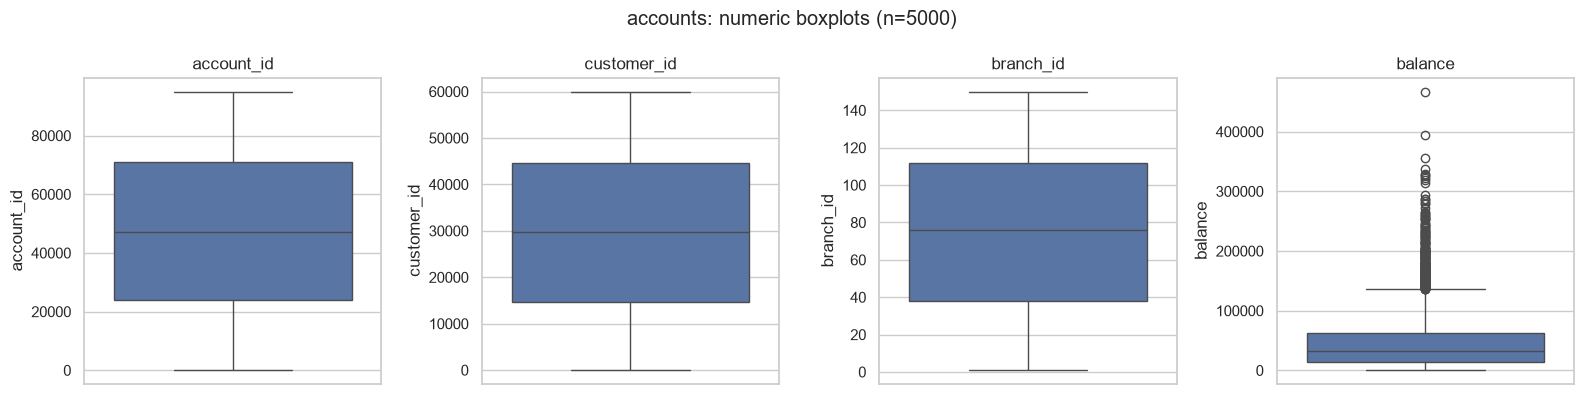

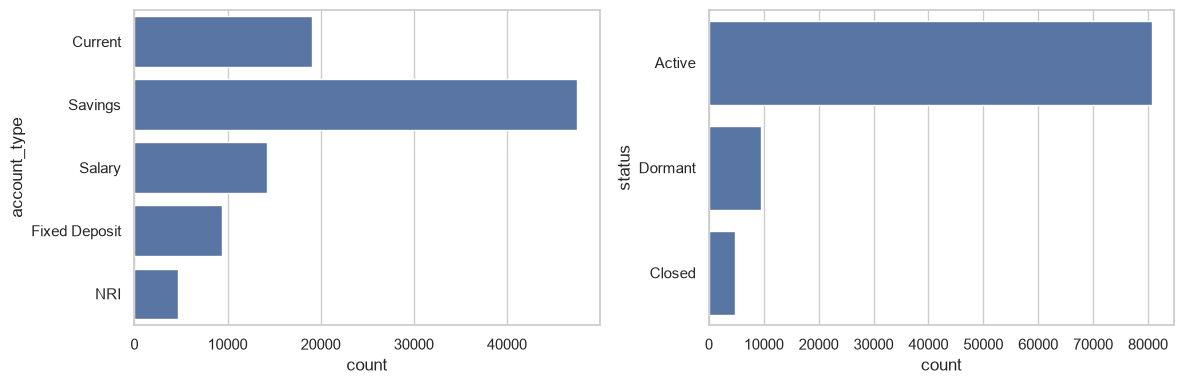

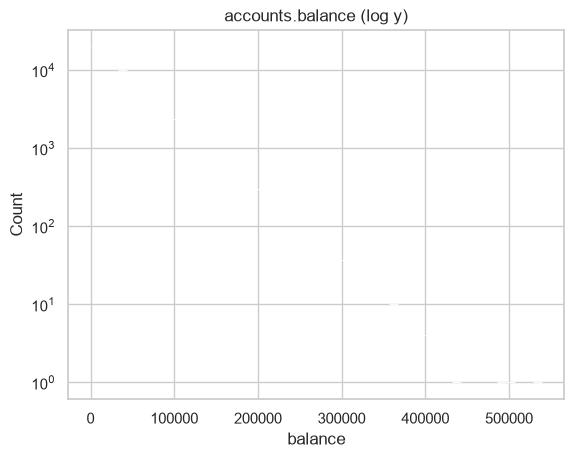

In [5]:
profile(accounts, "accounts")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(y=accounts["account_type"], ax=axes[0])
sns.countplot(y=accounts["status"], ax=axes[1])
plt.tight_layout(); plt.show()
sns.histplot(accounts["balance"], bins=50, log_scale=(False, True))
plt.title("accounts.balance (log y)"); plt.show()

### branches

--- branches ---
shape: (150, 8)
                      dtype  nulls  null_pct
branch_id             int64      0       0.0
branch_name             str      0       0.0
city                    str      0       0.0
state                   str      0       0.0
opened_date          object      0       0.0
ifsc_code               str      0       0.0
loaded_at    datetime64[us]      0       0.0
created_at   datetime64[us]      0       0.0


,branch_id,branch_name,city,state,opened_date,ifsc_code,loaded_at,created_at
0,1,Pune Branch 1,Pune,Maharashtra,2016-05-23,BNK0000000,2026-10-14 19:41:25.837045,2026-07-17 13:39:10
1,2,Bhopal Branch 2,Bhopal,Madhya Pradesh,2002-01-13,BNK0000001,2026-10-14 19:41:25.837045,2026-07-17 13:39:10
2,3,Lucknow Branch 3,Lucknow,Uttar Pradesh,2017-12-10,BNK0000002,2026-10-14 19:41:25.837045,2026-07-17 13:39:10


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
branch_id,150.0,NaN,NaN,NaN,75.5,1.0,38.25,75.5,112.75,150.0,43.445368
branch_name,150,93,Kochi Branch 2,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,150,15,Bhopal,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,150,12,Maharashtra,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
opened_date,150,148,2006-03-05,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ifsc_code,150,150,BNK0000000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loaded_at,150,NaN,NaN,NaN,2026-10-14 19:41:25.837044,2026-10-14 19:41:25.837045,2026-10-14 19:41:25.837045,2026-10-14 19:41:25.837045,2026-10-14 19:41:25.837045,2026-10-14 19:41:25.837045,NaN
created_at,150,NaN,NaN,NaN,2026-07-17 13:39:10,2026-07-17 13:39:10,2026-07-17 13:39:10,2026-07-17 13:39:10,2026-07-17 13:39:10,2026-07-17 13:39:10,NaN


no missing values


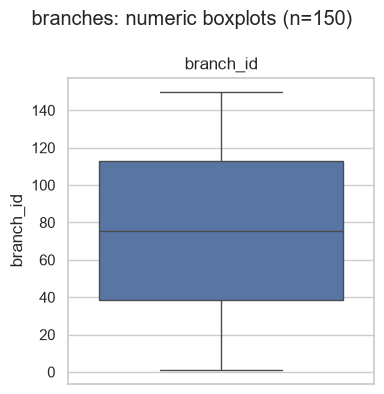

state
Maharashtra       25
Madhya Pradesh    24
West Bengal       15
Kerala            14
Punjab            11
Rajasthan         11
Gujarat           10
Uttar Pradesh      9
Delhi              9
Tamil Nadu         8
Name: count, dtype: int64


In [6]:
profile(branches, "branches")
print(branches["state"].value_counts().head(10))

### cards

--- cards ---
shape: (65000, 10)
                       dtype  nulls  null_pct
card_id                int64      0       0.0
customer_id            int64      0       0.0
account_id             int64      0       0.0
card_type                str      0       0.0
issue_date            object      0       0.0
expiry_date           object      0       0.0
credit_limit         float64      0       0.0
status                   str      0       0.0
loaded_at     datetime64[us]      0       0.0
created_at    datetime64[us]      0       0.0


,card_id,customer_id,account_id,card_type,issue_date,expiry_date,credit_limit,status,loaded_at,created_at
0,1,34846,75950,Credit - Gold,2018-12-05,2023-12-04,0.0,Active,2026-10-14 19:41:25.837045,2026-07-17 13:39:20
1,2,50151,55880,Credit - Classic,2016-05-19,2021-05-18,0.0,Active,2026-10-14 19:41:25.837045,2026-07-17 13:39:20
2,3,11246,86152,Credit - Gold,2023-08-30,2028-08-28,50000.0,Active,2026-10-14 19:41:25.837045,2026-07-17 13:39:20


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
card_id,65000.0,NaN,NaN,NaN,32500.5,1.0,16250.75,32500.5,48750.25,65000.0,18764.028086
customer_id,65000.0,NaN,NaN,NaN,29893.746385,1.0,14835.0,29845.5,44884.0,60000.0,17343.831523
account_id,65000.0,NaN,NaN,NaN,47651.2388,2.0,23856.75,47635.0,71683.25,95000.0,27455.220165
card_type,65000,4,Debit,35700,NaN,NaN,NaN,NaN,NaN,NaN,NaN
issue_date,65000,3804,2018-03-01,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
expiry_date,65000,3804,2023-02-28,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
credit_limit,65000.0,NaN,NaN,NaN,39608.461538,0.0,0.0,0.0,50000.0,500000.0,82944.876524
status,65000,3,Active,57214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loaded_at,65000,NaN,NaN,NaN,2026-10-14 19:41:25.837044,2026-10-14 19:41:25.837045,2026-10-14 19:41:25.837045,2026-10-14 19:41:25.837045,2026-10-14 19:41:25.837045,2026-10-14 19:41:25.837045,NaN
created_at,65000,NaN,NaN,NaN,2026-07-17 13:39:20,2026-07-17 13:39:20,2026-07-17 13:39:20,2026-07-17 13:39:20,2026-07-17 13:39:20,2026-07-17 13:39:20,NaN


no missing values


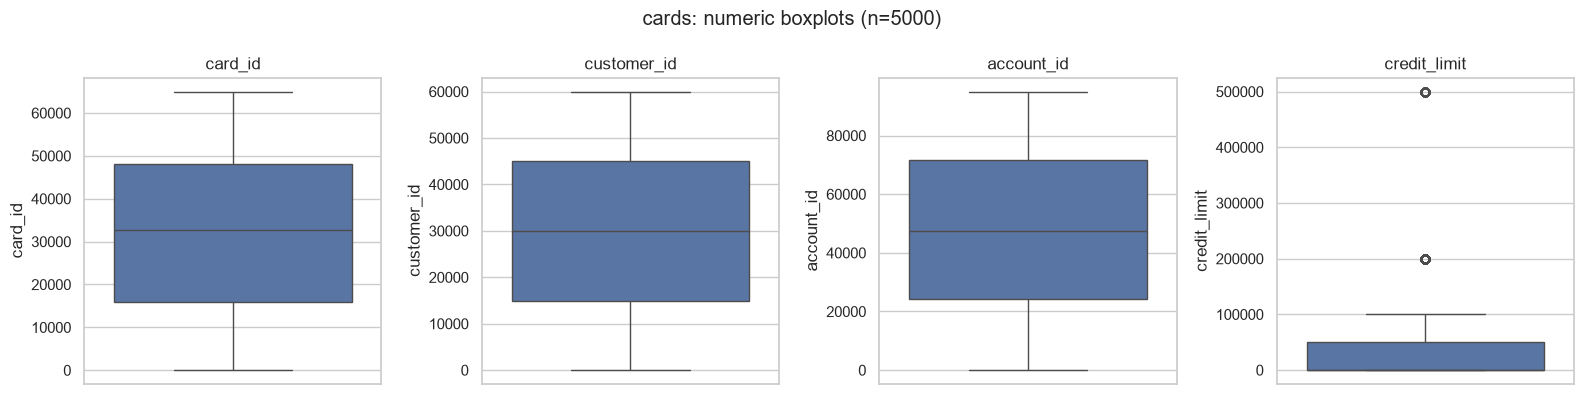

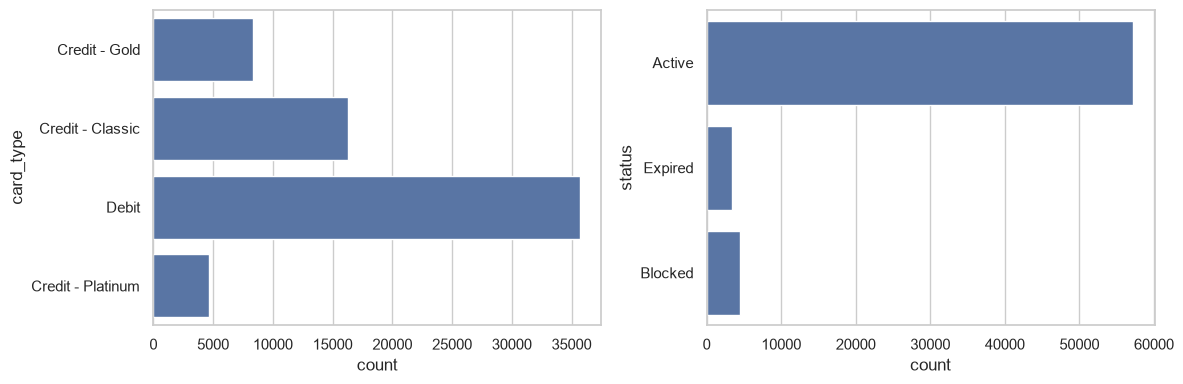

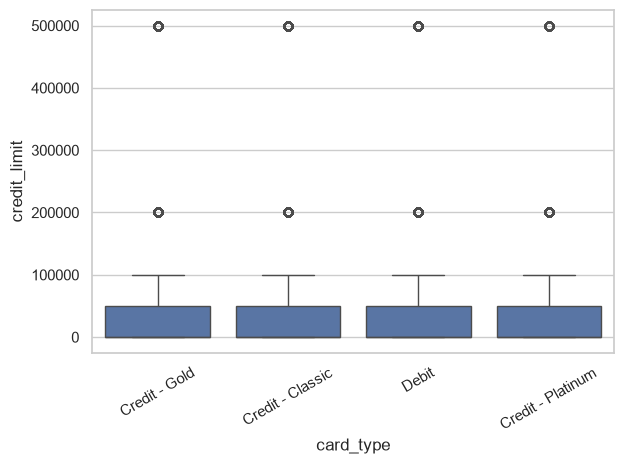

In [7]:
profile(cards, "cards")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(y=cards["card_type"], ax=axes[0])
sns.countplot(y=cards["status"], ax=axes[1])
plt.tight_layout(); plt.show()
sns.boxplot(data=cards, x="card_type", y="credit_limit")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

### customers

--- customers ---
shape: (60000, 14)
                        dtype  nulls  null_pct
customer_id             int64      0       0.0
name                      str      0       0.0
gender                    str      0       0.0
date_of_birth          object      0       0.0
city                      str      0       0.0
state                     str      0       0.0
phone                     str      0       0.0
email                     str      0       0.0
occupation                str      0       0.0
annual_income         float64      0       0.0
join_date              object      0       0.0
credit_score            int64      0       0.0
loaded_at      datetime64[us]      0       0.0
created_at     datetime64[us]      0       0.0


,customer_id,name,gender,date_of_birth,city,state,phone,email,occupation,annual_income,join_date,credit_score,loaded_at,created_at
0,1,Pooja Garcia,Male,1987-12-11,Ahmedabad,Gujarat,9562078082,customer0@mailbank.com,Retired,200025.0,2018-02-23,690,2026-10-14 19:41:25.837045,2026-07-17 13:39:22
1,2,Anjali Kapoor,Female,1965-12-18,Lucknow,Uttar Pradesh,9599825073,customer1@mailbank.com,Salaried - Government,1865003.0,2020-11-08,672,2026-10-14 19:41:25.837045,2026-07-17 13:39:22
2,3,James Smith,Female,1979-03-12,Chandigarh,Punjab,9572599111,customer2@mailbank.com,Salaried - Government,1709141.0,2007-04-22,422,2026-10-14 19:41:25.837045,2026-07-17 13:39:22


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
customer_id,60000.0,NaN,NaN,NaN,30000.5,1.0,15000.75,30000.5,45000.25,60000.0,17320.652413
name,60000,1230,Jessica Kapoor,73,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,60000,3,Male,31344,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_of_birth,60000,19051,1994-03-01,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,60000,15,Chandigarh,4123,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,60000,12,Maharashtra,11981,NaN,NaN,NaN,NaN,NaN,NaN,NaN
phone,60000,59995,9909323846,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
email,60000,60000,customer0@mailbank.com,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,60000,7,Freelancer,8651,NaN,NaN,NaN,NaN,NaN,NaN,NaN
annual_income,60000.0,NaN,NaN,NaN,1822024.140317,150085.0,988017.25,1825404.5,2654570.5,3499954.0,963874.754001


no missing values


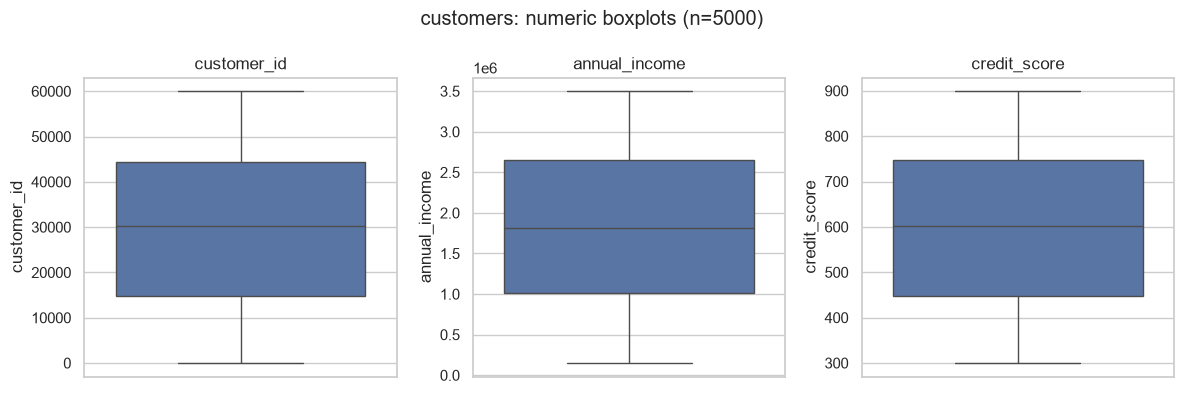

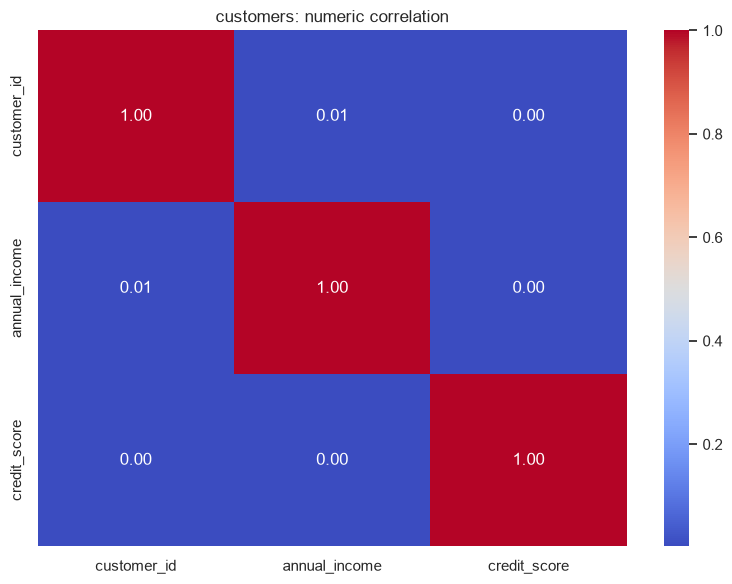

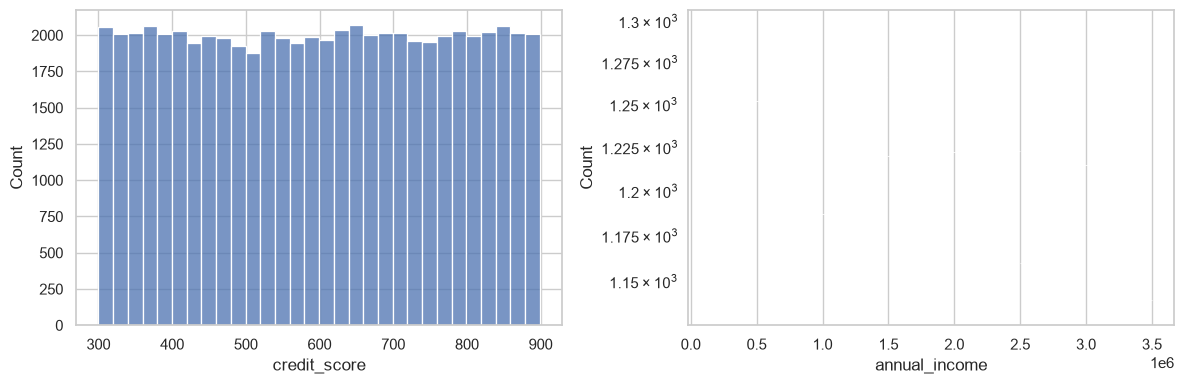

In [8]:
profile(customers, "customers")
num = customers.select_dtypes(include="number")
plt.figure(figsize=(8, 6))
sns.heatmap(num.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("customers: numeric correlation"); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(customers["credit_score"].dropna(), bins=30, ax=axes[0])
sns.histplot(customers["annual_income"].dropna(), bins=50, log_scale=(False, True), ax=axes[1])
plt.tight_layout(); plt.show()

### employees

--- employees ---
shape: (1800, 8)
                      dtype  nulls  null_pct
employee_id           int64      0       0.0
name                    str      0       0.0
branch_id             int64      0       0.0
role                    str      0       0.0
hire_date            object      0       0.0
salary              float64      0       0.0
loaded_at    datetime64[us]      0       0.0
created_at   datetime64[us]      0       0.0


,employee_id,name,branch_id,role,hire_date,salary,loaded_at,created_at
0,1,Richard Rodriguez,30,Customer Service,2016-11-09,62479.0,2026-10-14 19:41:25.837045,2026-07-17 13:39:22
1,2,Robert Rodriguez,136,Relationship Manager,2010-08-04,50855.0,2026-10-14 19:41:25.837045,2026-07-17 13:39:22
2,3,Arjun Rodriguez,35,Customer Service,2020-02-12,94948.0,2026-10-14 19:41:25.837045,2026-07-17 13:39:22


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
employee_id,1800.0,NaN,NaN,NaN,900.5,1.0,450.75,900.5,1350.25,1800.0,519.75956
name,1800,954,Richard Iyer,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
branch_id,1800.0,NaN,NaN,NaN,74.823333,1.0,39.0,75.0,113.0,150.0,43.086555
role,1800,6,Teller,673,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hire_date,1800,1631,2011-07-23,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary,1800.0,NaN,NaN,NaN,103739.217222,28063.0,65276.0,104710.0,141937.0,179802.0,43991.296888
loaded_at,1800,NaN,NaN,NaN,2026-10-14 19:41:25.837044,2026-10-14 19:41:25.837045,2026-10-14 19:41:25.837045,2026-10-14 19:41:25.837045,2026-10-14 19:41:25.837045,2026-10-14 19:41:25.837045,NaN
created_at,1800,NaN,NaN,NaN,2026-07-17 13:39:22,2026-07-17 13:39:22,2026-07-17 13:39:22,2026-07-17 13:39:22,2026-07-17 13:39:22,2026-07-17 13:39:22,NaN


no missing values


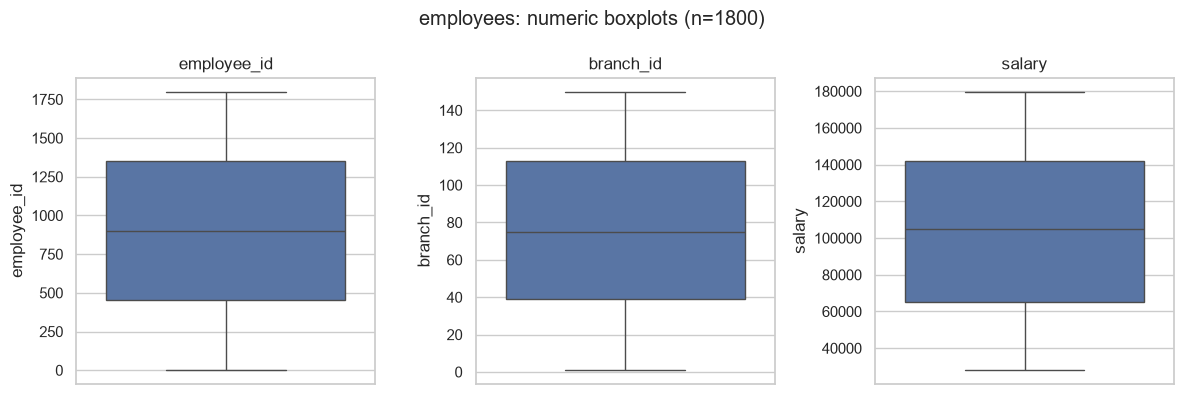

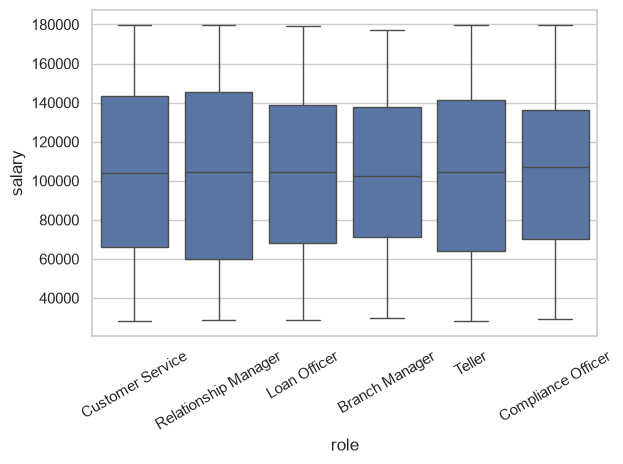

In [9]:
profile(employees, "employees")
sns.boxplot(data=employees, x="role", y="salary")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

## 4. Referential-integrity spot checks

In [10]:
print("accounts w/ unknown customer:",
      (~accounts["customer_id"].isin(customers["customer_id"])).mean().round(4))
print("cards w/ unknown account:",
      (~cards["account_id"].isin(accounts["account_id"])).mean().round(4))
print("employees w/ unknown branch:",
      (~employees["branch_id"].isin(branches["branch_id"])).mean().round(4))

accounts w/ unknown customer: 0.0
cards w/ unknown account: 0.0
employees w/ unknown branch: 0.0
